# 03 — SFT vs zero-shot: why did SFT make the 0.5B model worse?

Inputs (*Add Input*): output of `00_data`, `01_zeroshot` and `02_sft` (needs `exp2_sft_0.5b/model`).
Greedy answers are reused from 01 / 02; this notebook only generates for pass@k.

| § | question |
|---|---|
| 1 | Is the accuracy drop real? (paired bootstrap CI) |
| 2 | Did SFT break problems the model already solved? (flips + McNemar) |
| 3 | Did answers get shorter, and is the drop on long multi-step problems? |
| 4 | Is gold text "unfamiliar" to the model? (per-token loss) |
| 5 | Did SFT reduce diversity? (pass@k) → matters for GRPO and rejection sampling |

KL(SFT ‖ zero-shot) moved to Exp 4 (compared with GRPO); error-type labeling to Exp 8.

Set the input paths in the config cell, run with `DEBUG = True` first (16 problems, 2 samples), then `False`.

In [1]:
DEBUG = False

## Imports

In [2]:
import json, logging, math, re, sys, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from scipy.stats import binomtest
from transformers import AutoModelForCausalLM, AutoTokenizer

## Config + input paths
Set `ZEROSHOT_DIR` and `SFT_DIR` to the Kaggle input folders of the 01 and 02 outputs.

In [3]:
CFG = dict(
    run_name="exp3_sft_vs_zeroshot", model_id="Qwen/Qwen2.5-0.5B-Instruct", seed=42, debug=DEBUG,
    n_boot=10_000,                        # bootstrap resamples for the confidence intervals
    n_samples=2 if DEBUG else 8,          # pass@k: samples per problem
    temperature=0.7,                      # pass@k sampling temperature
    max_new_tokens=512,                   # same as 01 / 02
    gen_batch_prompts=8,                  # prompts per generate call (x n_samples sequences)
    score_batch_size=8,                   # sequences per forward pass when scoring log-probs
    limit=16 if DEBUG else None,          # problems per dataset
)


DATA_DIR = Path("/kaggle/input/notebooks/tensorpanda231/00-data-math-reasoning/data")   # 00 output
ZEROSHOT_DIR = Path("/kaggle/input/notebooks/tensorpanda231/01-zeroshot-qwen2-5-0-5b/exp1_zeroshot_0.5b")   
SFT_DIR = Path("/kaggle/input/notebooks/tensorpanda231/02-sft-0-5b/exp2_sft_0.5b")        
OUT_DIR = Path("/kaggle/working") / (CFG["run_name"] + ("_debug" if DEBUG else ""))

assert (DATA_DIR / "gsm8k_test.jsonl").exists(), f"DATA_DIR is wrong: {DATA_DIR}"
assert (ZEROSHOT_DIR / "predictions_gsm8k.jsonl").exists(), f"set ZEROSHOT_DIR in this cell (now: {ZEROSHOT_DIR})"
assert (SFT_DIR / "predictions_gsm8k.jsonl").exists() and (SFT_DIR / "model").exists(), f"set SFT_DIR in this cell (now: {SFT_DIR})"
(OUT_DIR / "plots").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "config.json").write_text(json.dumps(
    {**CFG, "zeroshot_dir": str(ZEROSHOT_DIR), "sft_dir": str(SFT_DIR), "torch": torch.__version__,
     "transformers": transformers.__version__}, indent=2))

508

## Logging + plot helper

In [4]:
NOTEBOOK_START_TIME = time.time()
logging.basicConfig(
    level=logging.WARNING, format="%(asctime)s | %(name)-9s | %(message)s", datefmt="%H:%M:%S", force=True,
    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(OUT_DIR / "run.log")],
)
def get_logger(name):
    logger = logging.getLogger(name)
    logger.setLevel(logging.INFO)
    return logger

log = get_logger("main")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

def fmt_time(seconds):
    return f"{int(seconds // 60)}m{int(seconds % 60):02d}s"

def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "plots" / filename, dpi=120)
    plt.show()

summary = {}      # every number reported below goes in here -> metrics.json
log.info(f"zero-shot: {ZEROSHOT_DIR} | sft: {SFT_DIR} | out: {OUT_DIR}")

07:22:20 | main      | zero-shot: /kaggle/input/notebooks/tensorpanda231/01-zeroshot-qwen2-5-0-5b/exp1_zeroshot_0.5b | sft: /kaggle/input/notebooks/tensorpanda231/02-sft-0-5b/exp2_sft_0.5b | out: /kaggle/working/exp3_sft_vs_zeroshot


## Greedy predictions from 01 and 02
Same problems in the same order, so every comparison below is **paired** (same problem, two models).

In [5]:
zeroshot_preds, sft_preds = {}, {}
for dataset in ["gsm8k", "svamp"]:
    zeroshot_preds[dataset] = pd.read_json(ZEROSHOT_DIR / f"predictions_{dataset}.jsonl", lines=True, dtype={"gold": str, "pred": str})
    sft_preds[dataset] = pd.read_json(SFT_DIR / f"predictions_{dataset}.jsonl", lines=True, dtype={"gold": str, "pred": str})
    if CFG["limit"]:
        zeroshot_preds[dataset] = zeroshot_preds[dataset].head(CFG["limit"])
        sft_preds[dataset] = sft_preds[dataset].head(CFG["limit"])
    assert (zeroshot_preds[dataset].question == sft_preds[dataset].question).all(), f"{dataset}: problems differ between 01 and 02"
    log.info(f"{dataset}: {len(zeroshot_preds[dataset])} problems | "
             f"zero-shot acc {zeroshot_preds[dataset].correct.mean():.3f} | sft acc {sft_preds[dataset].correct.mean():.3f}")

07:22:20 | main      | gsm8k: 1319 problems | zero-shot acc 0.437 | sft acc 0.327
07:22:21 | main      | svamp: 1000 problems | zero-shot acc 0.537 | sft acc 0.355


## §1 Accuracy with 95% bootstrap CI
Resample problems with replacement `n_boot` times and recompute accuracy each time; the 2.5 / 97.5 percentiles are the CI.
The same resampled problems are used for both models, so the CI of the **difference** is paired (much tighter than comparing two separate CIs).

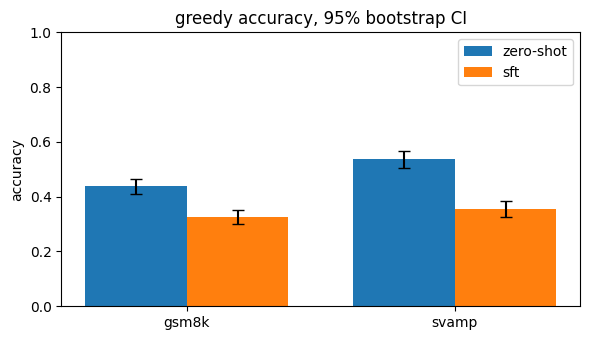

,dataset,model,accuracy,ci_low,ci_high
0,gsm8k,zero-shot,0.4375,0.4101,0.4647
1,gsm8k,sft,0.3268,0.3017,0.3518
2,gsm8k,sft - zero-shot,-0.1107,-0.1418,-0.0804
3,svamp,zero-shot,0.5370,0.5060,0.5680
4,svamp,sft,0.3550,0.3250,0.3850
5,svamp,sft - zero-shot,-0.1820,-0.2160,-0.1480


In [6]:
rng = np.random.default_rng(CFG["seed"])
table_rows = []
for dataset in zeroshot_preds:
    zeroshot_correct = zeroshot_preds[dataset].correct.to_numpy(float)
    sft_correct = sft_preds[dataset].correct.to_numpy(float)
    n_problems = len(zeroshot_correct)
    resampled_problem_ids = rng.integers(0, n_problems, size=(CFG["n_boot"], n_problems))   # [n_boot, n_problems]
    for model_name, correct in [("zero-shot", zeroshot_correct), ("sft", sft_correct),
                                ("sft - zero-shot", sft_correct - zeroshot_correct)]:
        bootstrap_accuracies = correct[resampled_problem_ids].mean(axis=1)                  # [n_boot]
        table_rows.append(dict(dataset=dataset, model=model_name, accuracy=correct.mean(),
                               ci_low=np.percentile(bootstrap_accuracies, 2.5),
                               ci_high=np.percentile(bootstrap_accuracies, 97.5)))
accuracy_ci = pd.DataFrame(table_rows).round(4)
summary["accuracy_ci"] = accuracy_ci.to_dict("records")

fig, ax = plt.subplots(figsize=(6, 3.5))
bar_positions, bar_width = np.arange(len(zeroshot_preds)), 0.38
for j, model_name in enumerate(["zero-shot", "sft"]):
    rows = accuracy_ci[accuracy_ci.model == model_name]
    ax.bar(bar_positions + (j - 0.5) * bar_width, rows.accuracy, bar_width, capsize=4, label=model_name,
           yerr=[rows.accuracy - rows.ci_low, rows.ci_high - rows.accuracy])
ax.set_xticks(bar_positions, list(zeroshot_preds)); ax.set_ylim(0, 1)
ax.set(ylabel="accuracy", title="greedy accuracy, 95% bootstrap CI"); ax.legend()
save_show(fig, "accuracy_ci.png")
accuracy_ci

## §2 Per-problem flips + McNemar test
Rows = zero-shot, columns = SFT. A large *right → wrong* count means SFT **broke** problems the base model could already solve,
not just "failed to improve".

McNemar: only problems where the models **disagree** carry information. If SFT made no real difference, each disagreement is a
coin flip: right_to_wrong ~ Binomial(right_to_wrong + wrong_to_right, 0.5). Exact two-sided test.

In [7]:
summary["flips"] = {}
for dataset in zeroshot_preds:
    zeroshot_correct, sft_correct = zeroshot_preds[dataset].correct, sft_preds[dataset].correct
    flip_table = pd.crosstab(zeroshot_correct.map({True: "right", False: "wrong"}).rename("zero-shot"),
                             sft_correct.map({True: "right", False: "wrong"}).rename("sft"))
    n_solved_by_zeroshot = max(int(zeroshot_correct.sum()), 1)
    right_to_wrong = int((zeroshot_correct & ~sft_correct).sum())
    wrong_to_right = int((~zeroshot_correct & sft_correct).sum())
    n_disagree = right_to_wrong + wrong_to_right
    mcnemar_p = binomtest(right_to_wrong, n_disagree, 0.5).pvalue if n_disagree else 1.0
    summary["flips"][dataset] = dict(
        right_to_right=int((zeroshot_correct & sft_correct).sum()), right_to_wrong=right_to_wrong,
        wrong_to_right=wrong_to_right, wrong_to_wrong=int((~zeroshot_correct & ~sft_correct).sum()),
        broken_share_of_solved=round(right_to_wrong / n_solved_by_zeroshot, 4), mcnemar_p=mcnemar_p)
    print(f"=== {dataset}: SFT broke {right_to_wrong}/{n_solved_by_zeroshot} "
          f"({right_to_wrong / n_solved_by_zeroshot:.0%}) of the problems zero-shot solved | "
          f"McNemar exact p = {mcnemar_p:.2g}")
    print(flip_table, "\n")

# 3 GSM8K examples that went right -> wrong, both answers side by side
zeroshot_gsm8k, sft_gsm8k = zeroshot_preds["gsm8k"], sft_preds["gsm8k"]
broken_problem_ids = zeroshot_gsm8k.index[zeroshot_gsm8k.correct & ~sft_gsm8k.correct]
for problem_id in broken_problem_ids[:3]:
    print(f"########## gold={zeroshot_gsm8k.gold[problem_id]}\n{zeroshot_gsm8k.question[problem_id]}")
    print(f"--- zero-shot (right, {zeroshot_gsm8k.n_tokens[problem_id]} tokens) ---\n{zeroshot_gsm8k.response[problem_id]}")
    print(f"--- sft (wrong, {sft_gsm8k.n_tokens[problem_id]} tokens) ---\n{sft_gsm8k.response[problem_id]}\n")

=== gsm8k: SFT broke 283/577 (49%) of the problems zero-shot solved | McNemar exact p = 8.9e-13
sft        right  wrong
zero-shot              
right        294    283
wrong        137    605 

=== svamp: SFT broke 257/537 (48%) of the problems zero-shot solved | McNemar exact p = 1.8e-24
sft        right  wrong
zero-shot              
right        280    257
wrong         75    388 

########## gold=3
A robe takes 2 bolts of blue fiber and half that much white fiber.  How many bolts in total does it take?
--- zero-shot (right, 189 tokens) ---
To determine the total number of bolts needed for the robe, we need to calculate the amount of each type of fiber required and then sum them up.

1. **Blue Fiber:**
   - It takes 2 bolts of blue fiber.
   - Therefore, the number of bolts of blue fiber is \(2\).

2. **White Fiber:**
   - It takes half as much white fiber as blue fiber.
   - Since 2 bolts of blue fiber require 2 bolts of white fiber, half this amount is \(\frac{2}{2} = 1\) bolt of 

## §3a Answer length
Token counts of greedy answers (zero-shot, SFT) and of the gold solutions SFT was trained to imitate (GSM8K only; SVAMP has no gold solution).

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

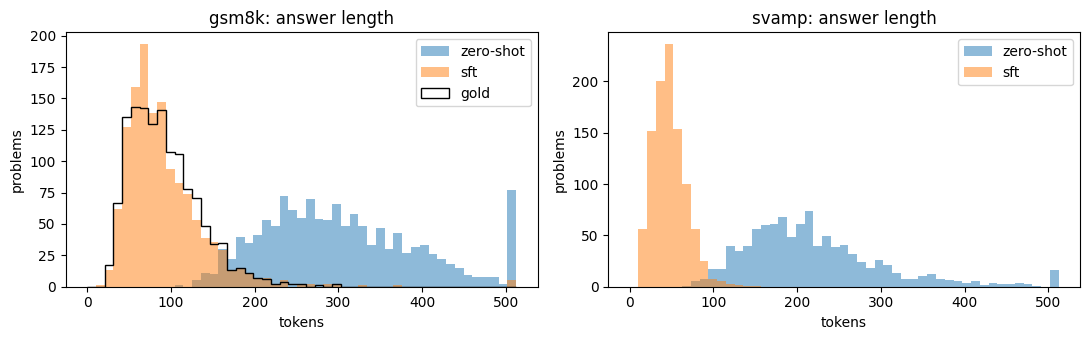

,gsm8k,svamp
zero-shot,292.0,206.0
sft,81.0,46.0
gold,86.0,NaN


In [8]:
tokenizer = AutoTokenizer.from_pretrained(CFG["model_id"], padding_side="left")
gold_solution_tokens = zeroshot_preds["gsm8k"].solution.map(lambda solution: len(tokenizer(solution).input_ids))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
length_bins = np.linspace(0, CFG["max_new_tokens"], 50)
for ax, dataset in zip(axes, zeroshot_preds):
    ax.hist(zeroshot_preds[dataset].n_tokens, length_bins, alpha=0.5, label="zero-shot")
    ax.hist(sft_preds[dataset].n_tokens, length_bins, alpha=0.5, label="sft")
    if dataset == "gsm8k":
        ax.hist(gold_solution_tokens, length_bins, histtype="step", lw=2, color="k", label="gold")
    ax.set(title=f"{dataset}: answer length", xlabel="tokens", ylabel="problems"); ax.legend()
save_show(fig, "lengths.png")

median_tokens = pd.DataFrame({dataset: {"zero-shot": zeroshot_preds[dataset].n_tokens.median(),
                                        "sft": sft_preds[dataset].n_tokens.median()} for dataset in zeroshot_preds})
median_tokens.loc["gold", "gsm8k"] = gold_solution_tokens.median()
summary["median_tokens"] = median_tokens.to_dict()
median_tokens

## §3b Accuracy by number of steps in the gold solution (GSM8K)
Steps = lines of the gold solution, not counting the `####` line. If SFT hurts mostly on 5+ step problems,
the short imitated style is not enough "thinking" for hard problems.

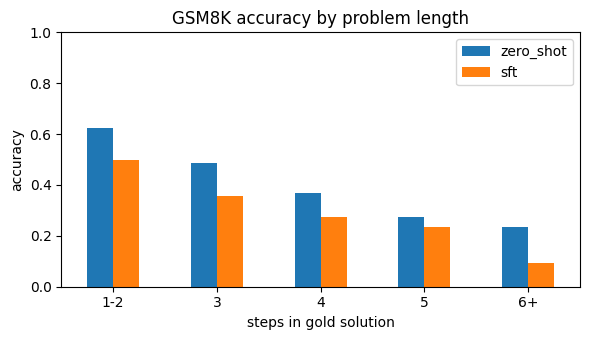

,n_problems,zero_shot,sft,drop
steps,,,,
1-2,326,0.623,0.497,-0.126
3,371,0.488,0.358,-0.129
4,297,0.370,0.273,-0.098
5,175,0.274,0.234,-0.040
6+,150,0.233,0.093,-0.140


In [9]:
gold_step_counts = zeroshot_preds["gsm8k"].solution.map(
    lambda solution: sum(1 for line in solution.strip().split("\n") if line.strip() and not line.startswith("####")))
step_group = pd.cut(gold_step_counts, [0, 2, 3, 4, 5, 100], labels=["1-2", "3", "4", "5", "6+"])
accuracy_by_steps = (
    pd.DataFrame({"steps": step_group, "zero_shot": zeroshot_preds["gsm8k"].correct, "sft": sft_preds["gsm8k"].correct})
    .groupby("steps", observed=True)
    .agg(n_problems=("sft", "size"), zero_shot=("zero_shot", "mean"), sft=("sft", "mean"))
)
accuracy_by_steps["drop"] = accuracy_by_steps.sft - accuracy_by_steps.zero_shot
summary["accuracy_by_steps"] = accuracy_by_steps.round(4).reset_index().astype({"steps": str}).to_dict("records")

fig, ax = plt.subplots(figsize=(6, 3.5))
accuracy_by_steps[["zero_shot", "sft"]].plot.bar(ax=ax, rot=0)
ax.set(xlabel="steps in gold solution", ylabel="accuracy", title="GSM8K accuracy by problem length", ylim=(0, 1))
save_show(fig, "acc_by_steps.png")
accuracy_by_steps.round(3)

## Models: zero-shot on GPU 0, SFT on GPU 1
From here on we need the models (log-prob scoring and sampling). Each model lives on its own GPU and the two run in parallel threads.
`build_prompt` / `extract_pred` / `is_correct` are copied from 01 (keep identical).

In [10]:
INSTRUCTION = "Solve the problem step by step. End your answer with a final line of the form '#### <number>'."

def build_prompt(tok, question):
    msgs = [{"role": "user", "content": f"{question}\n\n{INSTRUCTION}"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

NUM_RE = re.compile(r"-?\d[\d,]*(?:\.\d+)?")

def extract_pred(text):
    if "####" in text:
        nums = NUM_RE.findall(text.split("####")[-1])
        if nums:
            return nums[0].replace(",", ""), True
    nums = NUM_RE.findall(text)
    return (nums[-1].replace(",", ""), False) if nums else (None, False)

def is_correct(pred, gold):
    try:
        return pred is not None and abs(float(pred) - float(gold)) < 1e-6
    except ValueError:
        return False

assert extract_pred("so 1,000 total\n#### 1,000") == ("1000", True)
assert extract_pred("#### -3") == ("-3", True)
assert extract_pred("no idea") == (None, False)
assert is_correct("18.00", "18") and not is_correct("17", "18") and not is_correct(None, "18")

devices = [f"cuda:{i}" for i in range(torch.cuda.device_count())] or ["cpu"]
dtype = torch.float16 if devices[0].startswith("cuda") else torch.float32
models = {
    "zero-shot": AutoModelForCausalLM.from_pretrained(CFG["model_id"], dtype=dtype).to(devices[0]).eval(),
    "sft": AutoModelForCausalLM.from_pretrained(SFT_DIR / "model", dtype=dtype).to(devices[-1]).eval(),
}
log.info(f"models: { {name: str(model.device) for name, model in models.items()} } | dtype {dtype}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

07:23:14 | main      | models: {'zero-shot': 'cuda:0', 'sft': 'cuda:1'} | dtype torch.float16


## Log-prob scoring helper
`token_logprobs(model, prompt_ids, completion_ids)` → for each example, a 1-D tensor with log p(token | everything before) for every **completion** token.
Used for §4 (per-token loss); the same helper will compute KL in Exp 4.

Shapes for a batch of B sequences padded to length T, vocab V:
- `logits[:, t]` is the prediction for token `t+1`, so drop the last position: `[B, T-1, V]`
- `log_softmax` over V, then `gather` the token that actually came next (`input_ids[:, 1:]`) → `[B, T-1]`
- completion token k sits at position `len(prompt) + k`, so it is predicted by position `len(prompt) + k - 1`

Check: averaging it reproduces the loss of `model(labels=...)` with the prompt set to -100 (the SFT loss).

In [11]:
@torch.inference_mode()
def token_logprobs(model, prompt_ids, completion_ids):
    all_completion_logprobs, batch_size = [], CFG["score_batch_size"]
    for start in range(0, len(prompt_ids), batch_size):
        batch_prompts = prompt_ids[start:start + batch_size]
        batch_completions = completion_ids[start:start + batch_size]
        sequences = [prompt + completion for prompt, completion in zip(batch_prompts, batch_completions)]

        input_ids = torch.full((len(sequences), max(map(len, sequences))), tokenizer.pad_token_id)   # [B, T], right padding
        attention_mask = torch.zeros_like(input_ids)
        for row, sequence in enumerate(sequences):
            input_ids[row, :len(sequence)] = torch.tensor(sequence)
            attention_mask[row, :len(sequence)] = 1
        input_ids, attention_mask = input_ids.to(model.device), attention_mask.to(model.device)

        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits[:, :-1].float()      # [B, T-1, V]
        next_token_logprobs = torch.log_softmax(logits, dim=-1).gather(-1, input_ids[:, 1:, None]).squeeze(-1)  # [B, T-1]

        for row, (prompt, completion) in enumerate(zip(batch_prompts, batch_completions)):
            first = len(prompt) - 1                                                       # predicts completion token 0
            all_completion_logprobs.append(next_token_logprobs[row, first:first + len(completion)].cpu())   # [len(completion)]
    return all_completion_logprobs

# check against the HF loss on one example (prompt masked with -100, like SFT)
check_prompt_ids = tokenizer(build_prompt(tokenizer, "What is 2 + 3?")).input_ids
check_completion_ids = tokenizer("2 + 3 = 5\n#### 5").input_ids
check_model = models["zero-shot"]
check_input_ids = torch.tensor([check_prompt_ids + check_completion_ids], device=check_model.device)
check_labels = check_input_ids.clone()
check_labels[0, :len(check_prompt_ids)] = -100
with torch.inference_mode():
    hf_loss = check_model(input_ids=check_input_ids, labels=check_labels).loss.float().item()
our_logprobs = token_logprobs(check_model, [check_prompt_ids], [check_completion_ids])[0]
assert len(our_logprobs) == len(check_completion_ids)
assert abs(-our_logprobs.mean().item() - hf_loss) < 0.02, (-our_logprobs.mean().item(), hf_loss)
print(f"mean NLL: ours {-our_logprobs.mean().item():.4f} | HF loss {hf_loss:.4f}")

mean NLL: ours 0.8372 | HF loss 0.8372


## §4 Familiarity: is gold text "unfamiliar" to the model?
Ren et al. 2024 (*I Learn Better If You Speak My Language*): fine-tuning on text the model finds unlikely (high per-token loss) hurts more
than fine-tuning on text in its own style. Test: on GSM8K test problems the zero-shot model solved, compare the per-token loss (NLL) of
(a) the **gold solution** and (b) the model's **own correct answer**, both scored by the zero-shot model. Same problems, so paired.

07:23:48 | main      | familiarity: scored 577 problems x 2 texts in 0m32s
07:23:48 | main      | under the zero-shot model, gold is less likely than its own answer on 100% of problems


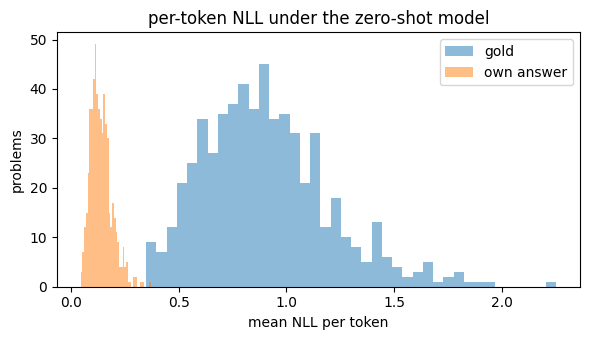

,text,mean_nll,perplexity
0,gold,0.906,2.476
1,own answer,0.139,1.149


In [12]:
solved_problems = zeroshot_preds["gsm8k"][zeroshot_preds["gsm8k"].correct].reset_index(drop=True)
solved_prompt_ids = [tokenizer(build_prompt(tokenizer, question)).input_ids for question in solved_problems.question]
texts_to_score = {"gold": solved_problems.solution.tolist(), "own answer": solved_problems.response.tolist()}

start_time = time.time()
mean_nll = {}     # text kind -> per-token NLL, one value per problem
for text_kind, texts in texts_to_score.items():
    completion_ids = [tokenizer(text).input_ids for text in texts]
    logprobs_list = token_logprobs(models["zero-shot"], solved_prompt_ids, completion_ids)
    mean_nll[text_kind] = np.array([-logprobs.mean().item() for logprobs in logprobs_list])
log.info(f"familiarity: scored {len(solved_problems)} problems x 2 texts in {fmt_time(time.time() - start_time)}")

familiarity = pd.DataFrame([dict(text=text_kind, mean_nll=values.mean(), perplexity=np.exp(values.mean()))
                            for text_kind, values in mean_nll.items()]).round(3)
gold_less_likely_share = (mean_nll["gold"] > mean_nll["own answer"]).mean()
summary["familiarity"] = dict(n_problems=len(solved_problems), table=familiarity.to_dict("records"),
                              gold_less_likely_share=round(float(gold_less_likely_share), 4))
log.info(f"under the zero-shot model, gold is less likely than its own answer on {gold_less_likely_share:.0%} of problems")

fig, ax = plt.subplots(figsize=(6, 3.5))
for text_kind in texts_to_score:
    ax.hist(mean_nll[text_kind], bins=40, alpha=0.5, label=text_kind)
ax.set(title="per-token NLL under the zero-shot model", xlabel="mean NLL per token", ylabel="problems"); ax.legend()
save_show(fig, "familiarity.png")
familiarity

## §5a Sampling for pass@k (GSM8K test)
`n_samples` answers per problem at `temperature`, both models at the same time (one per GPU).
`top_k=0, top_p=1, repetition_penalty=1` override Qwen's `generation_config.json` defaults (top_k 20, top_p 0.8, rep. penalty 1.05),
so we sample from the model's real distribution. Saved to `pass_at_{n}_samples_{model}.jsonl` (every sample, with question and gold);
if the file exists it is loaded instead (cheap rerun).

In [13]:
gsm8k_test = zeroshot_preds["gsm8k"]
gsm8k_prompts = [build_prompt(tokenizer, question) for question in gsm8k_test.question]

@torch.inference_mode()
def sample_answers(model_name):      # runs in one thread per model (= per GPU)
    samples_path = OUT_DIR / f"pass_at_{CFG['n_samples']}_samples_{model_name}.jsonl"
    if samples_path.exists():
        return pd.read_json(samples_path, lines=True, dtype={"gold": str, "pred": str})
    model_log, model = get_logger(model_name), models[model_name]
    prompts_per_batch, n_samples = CFG["gen_batch_prompts"], CFG["n_samples"]
    sample_rows, start_time = [], time.time()
    for batch_start in range(0, len(gsm8k_prompts), prompts_per_batch):
        encoded = tokenizer(gsm8k_prompts[batch_start:batch_start + prompts_per_batch],
                            return_tensors="pt", padding=True).to(model.device)
        generated = model.generate(**encoded, do_sample=True, temperature=CFG["temperature"], top_k=0, top_p=1.0,
                                   repetition_penalty=1.0, num_return_sequences=n_samples,
                                   max_new_tokens=CFG["max_new_tokens"], pad_token_id=tokenizer.pad_token_id)
        new_tokens = generated[:, encoded.input_ids.shape[1]:]   # [prompts * n_samples, L]; rows i*n .. i*n+n-1 = prompt i
        answer_lengths = (new_tokens != tokenizer.pad_token_id).sum(dim=1).tolist()
        answers = tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
        for row, (answer, n_tokens) in enumerate(zip(answers, answer_lengths)):
            problem_id = batch_start + row // n_samples
            pred, has_format = extract_pred(answer)
            sample_rows.append(dict(
                problem_id=problem_id, sample_id=row % n_samples, question=gsm8k_test.question[problem_id],
                gold=gsm8k_test.gold[problem_id], response=answer, pred=pred, has_format=has_format,
                correct=is_correct(pred, gsm8k_test.gold[problem_id]), n_tokens=n_tokens))
        n_done, elapsed = min(batch_start + prompts_per_batch, len(gsm8k_prompts)), time.time() - start_time
        model_log.info(f"sampling | {n_done}/{len(gsm8k_prompts)} problems | "
                       f"acc so far {np.mean([r['correct'] for r in sample_rows]):.3f} | "
                       f"elapsed {fmt_time(elapsed)} | ETA {fmt_time(elapsed / n_done * (len(gsm8k_prompts) - n_done))}")
    samples_df = pd.DataFrame(sample_rows)
    samples_df.to_json(samples_path, orient="records", lines=True)
    return samples_df

start_time = time.time()
with ThreadPoolExecutor(len(models)) as pool:
    samples = dict(zip(models, pool.map(sample_answers, models)))
log.info(f"sampling done in {fmt_time(time.time() - start_time)} | {sum(map(len, samples.values()))} answers")

07:24:02 | sft       | sampling | 8/1319 problems | acc so far 0.266 | elapsed 0m14s | ETA 39m01s
07:24:16 | zero-shot | sampling | 8/1319 problems | acc so far 0.344 | elapsed 0m27s | ETA 76m22s
07:24:19 | sft       | sampling | 16/1319 problems | acc so far 0.242 | elapsed 0m31s | ETA 42m11s
07:24:33 | sft       | sampling | 24/1319 problems | acc so far 0.214 | elapsed 0m44s | ETA 39m57s
07:24:41 | sft       | sampling | 32/1319 problems | acc so far 0.223 | elapsed 0m53s | ETA 35m43s
07:24:44 | zero-shot | sampling | 16/1319 problems | acc so far 0.320 | elapsed 0m56s | ETA 76m02s
07:25:09 | sft       | sampling | 40/1319 problems | acc so far 0.219 | elapsed 1m20s | ETA 42m53s
07:25:11 | zero-shot | sampling | 24/1319 problems | acc so far 0.328 | elapsed 1m23s | ETA 74m40s
07:25:21 | sft       | sampling | 48/1319 problems | acc so far 0.227 | elapsed 1m32s | ETA 40m44s
07:25:29 | sft       | sampling | 56/1319 problems | acc so far 0.254 | elapsed 1m40s | ETA 37m45s
07:25:38 | z

## §5b pass@k
Unbiased estimator (Chen et al. 2021): with n samples of which c are correct, pass@k = 1 − C(n−c, k) / C(n, k), averaged over problems.
If SFT's curve is flatter (less gain from more samples), it explores less.

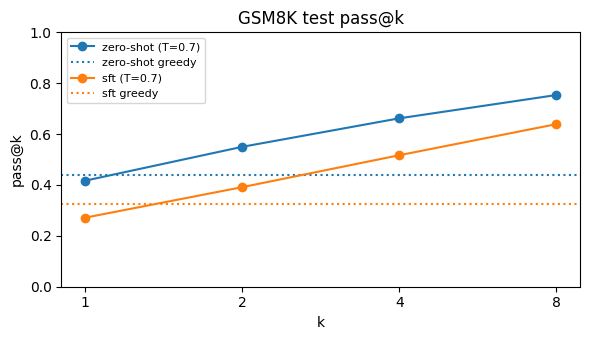

,zero-shot,sft
k,,
1,0.417,0.271
2,0.550,0.391
4,0.662,0.517
8,0.754,0.639


In [14]:
n_samples = CFG["n_samples"]
k_values = [k for k in [1, 2, 4, 8] if k <= n_samples]
# sanity: c = 0 correct -> 0, c = n correct -> 1
assert 1 - math.comb(n_samples, 1) / math.comb(n_samples, 1) == 0 and 1 - math.comb(0, 1) / math.comb(n_samples, 1) == 1

pass_at_k = pd.DataFrame({
    model_name: {k: np.mean([1 - math.comb(n_samples - n_correct, k) / math.comb(n_samples, k)
                             for n_correct in model_samples.groupby("problem_id").correct.sum()])
                 for k in k_values}
    for model_name, model_samples in samples.items()
}).rename_axis("k")
summary["pass_at_k"] = pass_at_k.round(4).to_dict()

greedy_accuracy = {"zero-shot": zeroshot_preds["gsm8k"].correct.mean(), "sft": sft_preds["gsm8k"].correct.mean()}
fig, ax = plt.subplots(figsize=(6, 3.5))
for model_name, color in zip(pass_at_k.columns, ["C0", "C1"]):
    ax.plot(k_values, pass_at_k[model_name], "o-", c=color, label=f"{model_name} (T={CFG['temperature']})")
    ax.axhline(greedy_accuracy[model_name], ls=":", c=color, label=f"{model_name} greedy")
ax.set_xscale("log", base=2); ax.set_xticks(k_values, k_values)
ax.set(xlabel="k", ylabel="pass@k", title="GSM8K test pass@k", ylim=(0, 1)); ax.legend(fontsize=8)
save_show(fig, "pass_at_k.png")
pass_at_k.round(3)

## §5c Diversity → is it a good GRPO starting point?
GRPO normalizes rewards **within** each group of samples for one prompt. A group where all samples are right (or all wrong) has
zero advantage → no gradient. So the share of **mixed** groups (0 < correct < n) is the share of prompts GRPO can learn from.

In [15]:
table_rows = []
for model_name, model_samples in samples.items():
    per_problem = model_samples.groupby("problem_id")
    n_correct = per_problem.correct.sum()
    table_rows.append(dict(
        model=model_name, sample_accuracy=n_correct.mean() / n_samples,
        distinct_answers=per_problem.pred.nunique().mean(),
        all_wrong=(n_correct == 0).mean(), mixed=((n_correct > 0) & (n_correct < n_samples)).mean(),
        all_right=(n_correct == n_samples).mean(), mean_tokens=model_samples.n_tokens.mean()))
diversity = pd.DataFrame(table_rows).set_index("model").round(3)
summary["diversity"] = diversity.to_dict("index")
diversity

,sample_accuracy,distinct_answers,all_wrong,mixed,all_right,mean_tokens
model,,,,,,
zero-shot,0.417,4.505,0.246,0.656,0.098,304.944
sft,0.271,5.597,0.361,0.603,0.036,101.661


## §5d Save pass@k results per problem
One row per GSM8K test problem: how many of the `n_samples` were correct for each model, plus greedy correctness
→ `pass_at_{n}_per_problem.csv`. All individual samples are already in `pass_at_{n}_samples_{model}.jsonl`.



In [16]:
pass_at_n_per_problem = gsm8k_test[["question", "gold"]].copy()
for model_name, model_samples in samples.items():
    correct_per_problem = model_samples.groupby("problem_id").correct.sum()
    pass_at_n_per_problem[f"{model_name}_n_correct"] = correct_per_problem.reindex(pass_at_n_per_problem.index).values
    pass_at_n_per_problem[f"{model_name}_greedy_correct"] = {"zero-shot": zeroshot_preds, "sft": sft_preds}[model_name]["gsm8k"].correct.values
pass_at_n_path = OUT_DIR / f"pass_at_{n_samples}_per_problem.csv"
pass_at_n_per_problem.to_csv(pass_at_n_path, index_label="problem_id")
log.info(f"saved {pass_at_n_path.name}: {len(pass_at_n_per_problem)} problems")
pass_at_n_per_problem.head()

08:37:41 | main      | saved pass_at_8_per_problem.csv: 1319 problems


,question,gold,zero-shot_n_correct,zero-shot_greedy_correct,sft_n_correct,sft_greedy_correct
0,Janet’s ducks lay 16 eggs per day. She eats th...,18,4,False,1,False
1,A robe takes 2 bolts of blue fiber and half th...,3,6,True,1,False
2,Josh decides to try flipping a house. He buys...,70000,0,False,0,False
3,James decides to run 3 sprints 3 times a week....,540,5,True,7,False
4,"Every day, Wendi feeds each of her chickens th...",20,0,False,1,True


## Summary + save

In [17]:
on_gpu = devices[0].startswith("cuda")
summary["gpu_hours_session"] = round((time.time() - NOTEBOOK_START_TIME) * len(devices) / 3600, 3) if on_gpu else 0.0
(OUT_DIR / "metrics.json").write_text(json.dumps(
    summary, indent=2, default=lambda value: value.item() if hasattr(value, "item") else str(value)))

print(accuracy_ci.to_string(index=False), "\n")
print("flips\n", pd.DataFrame(summary["flips"]).T, "\n")
print("familiarity\n", familiarity, "\n")
print("pass@k\n", pass_at_k.round(3), "\n")
print(diversity)
for saved_file in sorted(OUT_DIR.rglob("*")):
    if saved_file.is_file():
        log.info(f"saved {saved_file.relative_to(OUT_DIR)} ({saved_file.stat().st_size / 1e6:.1f} MB)")

dataset           model  accuracy  ci_low  ci_high
  gsm8k       zero-shot    0.4375  0.4101   0.4647
  gsm8k             sft    0.3268  0.3017   0.3518
  gsm8k sft - zero-shot   -0.1107 -0.1418  -0.0804
  svamp       zero-shot    0.5370  0.5060   0.5680
  svamp             sft    0.3550  0.3250   0.3850
  svamp sft - zero-shot   -0.1820 -0.2160  -0.1480 

flips
        right_to_right  right_to_wrong  wrong_to_right  wrong_to_wrong  \
gsm8k           294.0           283.0           137.0           605.0   
svamp           280.0           257.0            75.0           388.0   

       broken_share_of_solved     mcnemar_p  
gsm8k                  0.4905  8.850149e-13  
svamp                  0.4786  1.823571e-24   

familiarity
          text  mean_nll  perplexity
0        gold     0.906       2.476
1  own answer     0.139       1.149 

pass@k
    zero-shot    sft
k                  
1      0.417  0.271
2      0.550  0.391
4      0.662  0.517
8      0.754  0.639 

           sample_acc